<div style="background: linear-gradient(135deg, #0F2027, #203A43, #2C5364); 
            padding:40px; border-radius:15px; 
            box-shadow:0px 10px 30px rgba(0,0,0,0.3);">

<h1 style="color:#00E676; text-align:center; font-size:42px; margin:0; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;">
🍏 AAPL Open Price Forecasting
</h1>

<p style="color:#E0E0E0; text-align:center; font-size:20px; margin-top:15px; font-weight:300; letter-spacing:1px;">
A Comparative Study of LSTM, GRU, and Transformer Architectures
</p>

</div>

---

<div style="background-color:#F8F9FA; padding:30px; border-radius:12px; 
            box-shadow:0px 4px 15px rgba(0,0,0,0.08); 
            border-left: 6px solid #00E676;">

<h2 style="color:#0F2027; margin-top:0; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;">🔎 Project Overview</h2>

<p style="color:#333; font-size:16px; line-height:1.8;">
This notebook presents a comprehensive deep learning pipeline designed to forecast the <b>next-day Open price of Apple (AAPL)</b> stock. Moving beyond traditional raw price prediction, we engineer a <i>Log Return</i> target variable to eliminate the "lag" problem and capture true market momentum. The project rigorously compares three distinct neural network architectures: <b>LSTM, GRU, and Transformer</b>.
</p>

<h3 style="color:#0F2027; margin:25px 0 15px 0; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;">📋 What's Inside</h3>

<ul style="color:#333; font-size:16px; line-height:2; padding-left:20px;">
  <li><b>Feature Engineering</b> — Transforming raw prices into stationary <i>Log Returns</i> to prevent neural network "laziness" and lag effects.</li>
  <li><b>Model Architectures</b> — Implementing sequential models (LSTM, GRU) and a state-of-the-art <i>Transformer</i> with custom Positional Encoding for time-series awareness.</li>
  <li><b>Hyperparameter Tuning</b> — Utilizing <i>Keras Tuner (Hyperband)</i> to intelligently search for optimal layers, units, and learning rates without overfitting.</li>
  <li><b>Price Reconstruction</b> — Reversing the log transformation to evaluate models in real USD values.</li>
  <li><b>Performance Benchmarking</b> — Comparing models using Mean Absolute Error (MAE) and dynamic ranking tables.</li>
  <li><b>Visual & Residual Analysis</b> — Zoomed-in timeline comparisons and error (residual) plots to uncover the "Noise Ceiling" inherent in financial markets.</li>
</ul>

<hr style="border:none; border-top:1px solid #ddd; margin:25px 0;">

<p style="color:#555; font-size:14px; text-align:center; font-style:italic; margin-bottom: 20px;">
Best Model Achieved: <b>Transformer</b> with an MAE of <b>1.1089 USD</b>, proving the power of self-attention mechanisms in capturing complex temporal dependencies.
</p>

<!-- Related Project Link Section -->
<div style="background-color: #E8F5E9; padding: 15px; border-radius: 8px; text-align: center; border: 1px solid #C8E6C9;">
    <p style="color:#2E7D32; font-size:15px; margin: 0 0 10px 0; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;">
        💡 <b>Interested in a different approach?</b> Check out my previous project on predicting <i>Google Stock Prices</i> using classic RNN architectures.
    </p>
    <a href="https://www.kaggle.com/code/alipakzad/google-stock-price-prediction-lstm-gru-rnn" target="_blank" style="display: inline-block; background-color: #00E676; color: #0F2027; padding: 10px 20px; text-decoration: none; border-radius: 5px; font-weight: bold; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; transition: 0.3s;">
        📈 View Google Stock Project
    </a>
</div>

## <span style="display:block; padding:15px; background:linear-gradient(135deg, #0F2027, #203A43, #2C5364); margin:0; color:#00E676; font-family:'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-size:130%; text-align:center; border-radius:10px; overflow:hidden; font-weight:bold; box-shadow: 0px 4px 15px rgba(0,0,0,0.2); letter-spacing:1px;"> 📦 Import Libraries </span>

In [1]:
import tensorflow as tf
from tensorflow import keras
import keras_tuner as kt
import gc

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Input, Dense, Dropout, Concatenate
from tensorflow.keras import layers

import os
import json

# turn off warnings for final notebook
import warnings
warnings.filterwarnings('ignore')

In [7]:
apple_df = pd.read_csv("/kaggle/input/datasets/soheiltehranipour/apple-stock-20132018/AAPL.xls")

In [3]:
apple_df.isnull().sum()

Date    0
Open    0
dtype: int64

In [8]:
apple_df['Date'] = pd.to_datetime(apple_df['Date'])
apple_df.set_index('Date', inplace=True)

Text(0.5, 1.0, 'AAPL Stock Opening Price')

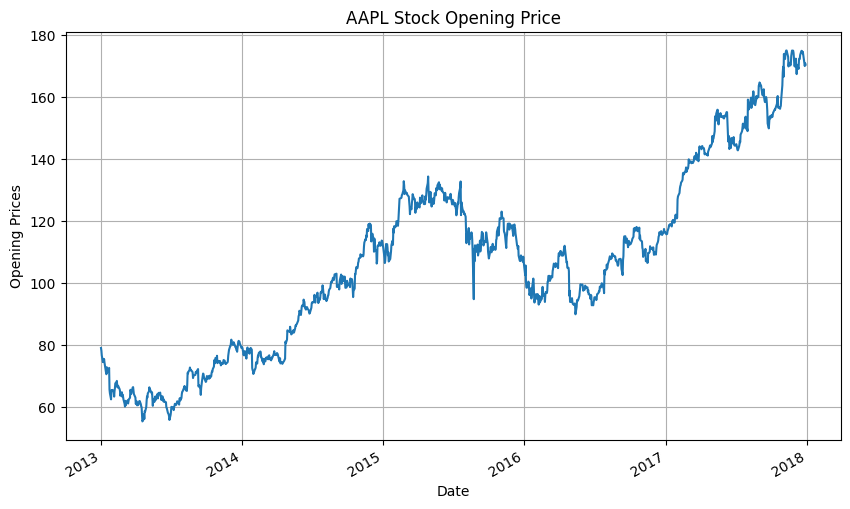

In [9]:
apple_df['Open'].plot(figsize=(10, 6))
plt.grid()

plt.xlabel('Date')
plt.ylabel('Opening Prices')
plt.title('AAPL Stock Opening Price')

### Why Predict Log Returns Instead of Raw Prices?

Instead of predicting the raw `Open` price directly, this notebook uses the **Log Return**. 
The log return is calculated as:

$$
\Large r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
$$

where $P_t$ is the price at time $t$ and $P_{t-1}$ is the price at the previous day.

**Reasons for using Log Returns:**
1. **Stationarity:** Raw stock prices are non-stationary (they trend upwards or downwards over time). Machine learning models struggle with this. Log returns oscillate around zero, providing a stable distribution for the model to learn.
2. **Avoiding the "Lag" Problem:** If we train a model directly on raw prices, the neural network often becomes "lazy" and simply predicts that tomorrow's price will be the same as today's. By predicting returns, the model is forced to learn the actual patterns and momentum of the market.
3. **Additivity:** Log returns are time-additive. The log return over two days is simply the sum of the individual daily log returns: $\ln(P_2/P_0) = \ln(P_1/P_0) + \ln(P_2/P_1)$.

### Reconstructing the Absolute Price

After the LSTM model predicts the future log returns, we must convert them back into absolute prices to evaluate the model and plot the results.

Using the inverse of the natural logarithm (the exponential function $e^x$), we can rearrange the formula:

$$
\Large P_{predicted} = P_{previous} \times e^{r_{predicted}}
$$

In the code, `np.exp()` is used to reverse the log transformation, and the result is multiplied by the actual previous day's price (`base_prices`) to reconstruct the final predicted `Open` price.

## <span style="display:block; padding:15px; background:linear-gradient(135deg, #0F2027, #203A43, #2C5364); margin:0; color:#00E676; font-family:'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-size:130%; text-align:center; border-radius:10px 10px 0 0; font-weight:bold; box-shadow: 0px 4px 15px rgba(0,0,0,0.1); letter-spacing:1px;"> ⚙️ Data Preparation </span>

<div style="background-color:#F8F9FA; padding:30px; border-radius:0 0 12px 12px; box-shadow:0px 4px 15px rgba(0,0,0,0.08); border-left: 6px solid #00E676; margin-top: 0;">

<p style="color:#333; font-size:16px; line-height:1.8; margin-top: 0;">
Before feeding the data into our Deep Learning architectures (LSTM, GRU, Transformer), we must format it correctly. Time-series models have specific requirements for input shapes and distributions. Here is the step-by-step pipeline used in this notebook:
</p>

<ol style="color:#333; font-size:16px; line-height:1.8; padding-left:20px; margin-bottom: 0;">
  <li><b>Chronological Train/Test Split:</b> The dataset is split into 80% training and 20% testing. Unlike standard ML, we strictly maintain the chronological order to prevent <i>Look-ahead Bias</i> (using future data to predict the past).</li>
  
  <li><b>Scaling & Preventing Data Leakage:</b> We normalize the <i>Log Returns</i> using a <code>MinMaxScaler</code>. Crucially, the scaler is fitted <b>only</b> on the training data and then applied to the test data. This simulates real-world scenarios where future market data is completely unknown.</li>
  
  <li><b>Windowing Function (<code>make_windows</code>):</b> Deep learning models require sequences. We define a sliding window function with a <b>lookback of 30 days</b> and a <b>forecast horizon of 1 day</b>. 
  <br><i>Why this is important:</i> This function maps 30 days of historical Log Returns to the Log Return of the very next day, allowing the model to learn temporal momentum and patterns.</li>
  
  <li><b>Tensorial Reshaping:</b> 
      <ul style="margin-top: 5px;">
        <li>The input array (<code>X</code>) is reshaped into a 3D tensor: <code>(samples, time_steps, features)</code>, which is strictly required by the first layer of RNN/Attention models.</li>
        <li>The target array (<code>y</code>) is reshaped into a 2D tensor: <code>(samples, y_steps)</code> to match the regression output of the dense layers.</li>
      </ul>
  </li>
</ol>

</div>

In [10]:
# ==========================================
# 1. Data Preparation (using Log Returns)
# ==========================================
# Calculate log returns based on the Open price
apple_df['log_return'] = np.log(apple_df['Open'] / apple_df['Open'].shift(1))
apple_df = apple_df.dropna() # Drop the first row which contains NaN

X_steps = 30   # 30-day lookback window
y_steps = 1    # 1-day forecast horizon

# Select the target as the log return
apple_timeseries = apple_df['log_return'].values.reshape(-1, 1)
N = len(apple_timeseries)

# Split data into train and test (80-20)
split_index = int(N * 0.8)
train = apple_timeseries[:split_index]
test = apple_timeseries[split_index - X_steps:] # Include extra X_steps for proper test windowing

# Scale the data
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train)
test_scaled = scaler.transform(test)

def make_windows(series, x_steps, y_steps):
    X, y = [], []
    T = len(series)
    for t in range(x_steps, T - y_steps + 1):
        X.append(series[t - x_steps:t])
        y.append(series[t:t + y_steps])
    return np.array(X), np.array(y)

X_train, y_train = make_windows(train_scaled, X_steps, y_steps)
X_test, y_test = make_windows(test_scaled, X_steps, y_steps)

y_train = y_train.reshape(y_train.shape[0], y_train.shape[1])
y_test = y_test.reshape(y_test.shape[0], y_test.shape[1])

## <span style="display:block; padding:15px; background:linear-gradient(135deg, #0F2027, #203A43, #2C5364); margin:0; color:#00E676; font-family:'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-size:130%; text-align:center; border-radius:10px; overflow:hidden; font-weight:bold; box-shadow: 0px 4px 15px rgba(0,0,0,0.2); letter-spacing:1px;"> 🧠 LSTM Architecture & Hyperparameter Tuning </span>

### Building and Optimizing the LSTM Model

In this section, we define and optimize our first deep learning architecture: the **Long Short-Term Memory (LSTM)** network. LSTMs are a special kind of Recurrent Neural Network (RNN) capable of learning long-term dependencies, making them highly suitable for time-series forecasting.

To find the best model for our specific AAPL dataset, we utilize **Keras Tuner** with the **Hyperband** algorithm. Here is a breakdown of what the following code does:

1. **Dynamic Architecture (`build_LSTM_model`):** Instead of hardcoding the network's shape, we define a search space. The tuner will automatically experiment with:
   * **Network Depth:** 1 or 2 hidden LSTM layers. *(Note: We intentionally restrict it to a maximum of 2 layers. Deeper networks almost always overfit on limited financial data).*
   * **Neurons (Units):** 32, 64, or 128 units per layer.
   * **Dropout:** A rate between 0.1 and 0.3 to prevent overfitting.
   * **Learning Rate:** A logarithmic search between \(10^{-4}\) and \(10^{-2}\) for the Adam optimizer.
   * **Loss Function:** We use **MAE (Mean Absolute Error)** because it is robust to outliers (sudden price spikes), unlike MSE which heavily penalizes large errors.

2. **Smart Search with Hyperband:** We use `Hyperband` because it is highly efficient. It runs many trials for a few epochs, discards the poorly performing ones, and only allows the most promising models to train for more epochs.

3. **Advanced Callbacks during Tuning:**
   * `ReduceLROnPlateau`: If the validation error stops improving, the learning rate is halved to help the model find a better minimum.
   * `EarlyStopping`: Stops training if the model hasn't improved in 7 epochs, saving valuable GPU time and preventing overfitting.

Finally, the code prints the **Best Hyperparameters** found by the tuner, which will be used to build and train the final model.

In [11]:
# ==========================================
# 2. Define the model building function for Keras Tuner
# ==========================================
def build_LSTM_model(hp):
    model = Sequential()
    
    # First LSTM layer
    units_0 = hp.Choice('units_layer_0', [32, 64, 128])
    model.add(keras.layers.LSTM(units_0, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
    model.add(keras.layers.Dropout(hp.Float('dropout_0', 0.1, 0.3, step=0.1)))
    
    # Decide on the second layer (only 1 or 2 layers to prevent overfitting)
    n_hidden_layers = hp.Int('n_hidden_layers', 1, 2, step=1) 
    
    for i in range(1, n_hidden_layers): # Start from 1 since the first layer is already built
        units_i = hp.Choice(f'units_layer_{i}', [32, 64, 128])
        # Set return_sequences=False if it's the last layer
        return_seq = (i < n_hidden_layers - 1) 
        model.add(keras.layers.LSTM(units_i, return_sequences=return_seq))
        model.add(keras.layers.Dropout(hp.Float(f'dropout_{i}', 0.1, 0.3, step=0.1)))
        
    # If we only have one layer, flatten the output for the Dense layer
    if n_hidden_layers == 1:
        model.add(keras.layers.Flatten())

    # Output layer
    model.add(keras.layers.Dense(y_steps))
    
    # Compile the model
    model.compile(
        optimizer=keras.optimizers.Adam(
            hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='log')
        ),
        loss="mae",
        metrics=['mae']
    )
    return model

# ==========================================
# 3. Tuner configuration and running the search
# ==========================================
# Use Hyperband for high speed
# Define callbacks for the TUNING phase (No ModelCheckpoint here!)
tuner_callbacks = [
    # Reduce learning rate when the metric has stopped improving
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_mae", factor=0.5, patience=4, min_lr=1e-5, verbose=0
    ),
    # Stop training when the metric stops improving
    keras.callbacks.EarlyStopping(
        monitor="val_mae", patience=7, restore_best_weights=True, verbose=1
    )
]

# Hyperband Configuration
tuner = kt.Hyperband(
    build_LSTM_model,
    objective='val_mae',
    max_epochs=50,
    factor=3,
    directory='kt_dir',
    project_name='apple_lstm_tuned',
    overwrite=True
)

# Run the search (limiting to 10-15 trials is sufficient)
tuner.search(
    X_train, y_train, 
    epochs=30, 
    validation_split=0.1, 
    callbacks= tuner_callbacks, 
    shuffle=False,
    verbose=1
)

# Get the best hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print()
print(f"Best HPs: {best_hps.values}")

Trial 90 Complete [00h 00m 08s]
val_mae: 0.02870362624526024

Best val_mae So Far: 0.027689456939697266
Total elapsed time: 00h 07m 11s

Best HPs: {'units_layer_0': 128, 'dropout_0': 0.2, 'n_hidden_layers': 2, 'learning_rate': 0.004985102094644402, 'units_layer_1': 64, 'dropout_1': 0.2, 'tuner/epochs': 50, 'tuner/initial_epoch': 17, 'tuner/bracket': 2, 'tuner/round': 2, 'tuner/trial_id': '0068'}


**Final Model Training:** Now that the tuner has identified our optimal hyperparameters, we build the final LSTM architecture. We then train this definitive model, utilizing callbacks to save the best weights, dynamically adapt the learning rate, and halt early to prevent overfitting.

In [12]:
# Define callbacks for the FINAL training phase
final_callbacks = [
    # Save the best model to disk during final training
    keras.callbacks.ModelCheckpoint(
        "best_apple_lstm.keras", save_best_only=True, monitor="val_mae", verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_mae", factor=0.5, patience=4, min_lr=1e-5, verbose=0
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_mae", patience=7, restore_best_weights=True, verbose=1
    )
]

# Build and train the final model with the best parameters
lstm_tuned_model = tuner.hypermodel.build(best_hps)
history = lstm_tuned_model.fit(
    X_train, y_train,
    epochs=100, 
    validation_split=0.1, 
    callbacks=final_callbacks
)

Epoch 1/100
22/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2142 - mae: 0.2142
Epoch 1: val_mae improved from None to 0.04085, saving model to best_apple_lstm.keras

Epoch 1: finished saving model to best_apple_lstm.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.1289 - mae: 0.1289 - val_loss: 0.0408 - val_mae: 0.0408 - learning_rate: 0.0050
Epoch 2/100
22/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0700 - mae: 0.0700
Epoch 2: val_mae improved from 0.04085 to 0.03553, saving model to best_apple_lstm.keras

Epoch 2: finished saving model to best_apple_lstm.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0614 - mae: 0.0614 - val_loss: 0.0355 - val_mae: 0.0355 - learning_rate: 0.0050
Epoch 3/100
25/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0530 - mae: 0.0530
Epoch 3: val_mae improved from 0.03553 to 0.03172, saving model to best_apple_lstm.keras

Epoch 3: finished saving model to best_apple_lstm.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0512 - mae: 0.0

**Model Evaluation & Price Reconstruction:** Here, we generate predictions on the test set and inverse-transform the scaled log returns back to their original values. To evaluate real-world performance, we reconstruct the absolute Open prices using the exponential formula $P_{pred} = P_{prev} \times e^{r_{pred}}$, and finally compute the Mean Absolute Error (MAE) in USD.

In [13]:
# 1. Predict
predictions_scaled = lstm_tuned_model.predict(X_test)

# 2. Inverse transform to original scale (model output is a scaled log_return)
predicted_log_returns = scaler.inverse_transform(predictions_scaled)
actual_log_returns = scaler.inverse_transform(y_test)

# 3. Reconstruct the original Open prices
# Since our test set starts from index split_index - X_steps:
# The base prices for reconstruction are the Open prices X_steps before the test set
base_prices = apple_df['Open'].values[split_index - X_steps : split_index - X_steps + len(predicted_log_returns)]

# Predicted price = previous price * e^(predicted log return)
lstm_predicted_prices = base_prices * np.exp(predicted_log_returns.flatten())
actual_prices = base_prices * np.exp(actual_log_returns.flatten())

# Calculate error
lstm_mae = mean_absolute_error(actual_prices, lstm_predicted_prices)
print(f"MAE for Reconstructed Open Prices: {round(lstm_mae, 3)}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
MAE for Reconstructed Open Prices: 1.12


**Visualization Helper Function:** We created this reusable `plot_model_results` function to ensure visual consistency across our project. Instead of rewriting plotting code for every model, this function dynamically standardizes the layout, formatting the X-axis dates, and automatically injecting the specific model's name and MAE score into the title. This allows us to generate identical, publication-ready charts for LSTM, GRU, and Transformer models with a single line of code.

In [14]:
def plot_model_results(dates, actual_prices, predicted_prices, model_name, mae_score):
    """
    Plots actual vs predicted prices with a professional layout.
    
    Parameters:
    dates (array-like): The dates for the x-axis.
    actual_prices (array-like): The true prices.
    predicted_prices (array-like): The model's predicted prices.
    model_name (str): Name of the model (e.g., 'LSTM', 'GRU', 'Transformer').
    mae_score (float): The MAE score to display in the title.
    """
    plt.figure(figsize=(14, 7))
    
    # Plot lines
    plt.plot(dates, actual_prices, label='Actual Open Price', color='black', linewidth=1.5)
    plt.plot(dates, predicted_prices, label=f'{model_name} Prediction', color='red', linewidth=1.5, alpha=0.8)
    
    # Dynamic Title including Model Name and MAE
    plt.title(f'Apple (AAPL) Open Price Prediction: {model_name}\n(MAE: {mae_score:.3f} USD)', 
              fontsize=16, fontweight='bold', pad=15)
    
    # Axis labels
    plt.xlabel('Date', fontsize=12, fontweight='bold')
    plt.ylabel('Stock Price (USD)', fontsize=12, fontweight='bold')
    
    # Legend
    plt.legend(loc='upper left', fontsize=12)
    
    # Format X-axis
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.gcf().autofmt_xdate()
    
    # Grid and Layout
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

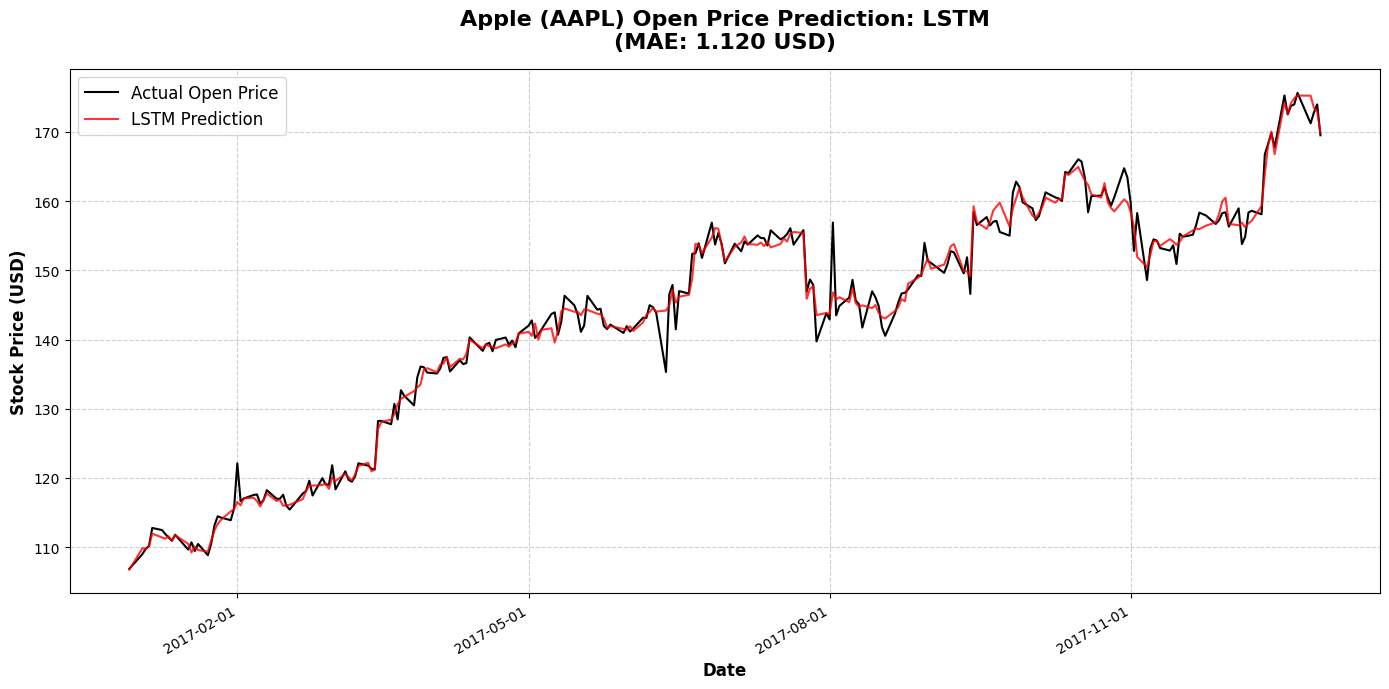

In [15]:
# extracting dates
test_dates = apple_df.index[split_index : split_index + len(lstm_predicted_prices)]

# plotting the predictions
plot_model_results(test_dates, actual_prices, lstm_predicted_prices, model_name="LSTM", mae_score=lstm_mae)

### LSTM Performance Analysis

The LSTM model achieved a **Mean Absolute Error (MAE) of 1.120 USD** on the unseen test data. As illustrated in the plot above, the model demonstrates an excellent ability to track the actual Open price across the entire test period (2017).

**Key Observations:**
* **Trend & Momentum Capture:** The predicted line (red) closely follows both the overall upward trend and the micro-fluctuations of the actual price (black). The use of *Log Returns* as the target variable successfully prevented the common "lagging" issue, allowing the model to predict the direction of the next day's price rather than just copying yesterday's value.
* **The "Smoothing" Effect:** During sudden, sharp market shocks (e.g., the steep drops in August 2017), the model exhibits a slight lag and predicts a smoother curve. This is a classic behavior in neural networks: when trained to minimize MAE, the model tends to regress toward the mean during high-volatility days. Since unexpected news cannot be inferred from historical prices alone, the model avoids extreme predictions to minimize overall risk.


## <span style="display:block; padding:15px; background:linear-gradient(135deg, #0F2027, #203A43, #2C5364); margin:0; color:#00E676; font-family:'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-size:130%; text-align:center; border-radius:10px; overflow:hidden; font-weight:bold; box-shadow: 0px 4px 15px rgba(0,0,0,0.2); letter-spacing:1px;"> ⚡ GRU Architecture & Hyperparameter Tuning </span>

### Building and Optimizing the GRU Model

After evaluating the LSTM, we now move to the **Gated Recurrent Unit (GRU)**. GRUs were introduced as a more computationally efficient alternative to LSTMs. By combining the input and forget gates into a single "update gate," GRUs often achieve similar or even superior performance to LSTMs on smaller datasets while significantly reducing training time and the number of parameters.

To ensure a fair comparison, we apply the exact same **Keras Tuner (Hyperband)** strategy used for the LSTM:

1. **Dynamic Architecture (`build_GRU_model`):** The tuner explores a similar search space:
   * **Network Depth:** 1 or 2 hidden GRU layers.
   * **Neurons (Units):** 32, 64, or 128 units per layer.
   * **Dropout:** Between 0.1 and 0.3.
   * **Learning Rate:** Logarithmic search between \(10^{-4}\) and \(10^{-2}\).
   * **Loss Function:** Mean Absolute Error (MAE).

2. **Smart Search & Callbacks:** We utilize Hyperband alongside `ReduceLROnPlateau` and `EarlyStopping` to efficiently navigate the search space, halting poor-performing trials early to save computational resources.

Finally, the best hyperparameters for the GRU are extracted and printed.

In [16]:
tf.keras.backend.clear_session()
gc.collect()

# 1. Define the model building function for GRU
def build_GRU_model(hp):
    model = Sequential()
    
    # First GRU layer
    units_0 = hp.Choice('units_layer_0', [32, 64, 128])
    model.add(keras.layers.GRU(units_0, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
    model.add(keras.layers.Dropout(hp.Float('dropout_0', 0.1, 0.3, step=0.1)))
    
    # Decide on the second layer (only 1 or 2 layers)
    n_hidden_layers = hp.Int('n_hidden_layers', 1, 2, step=1) 
    
    for i in range(1, n_hidden_layers):
        units_i = hp.Choice(f'units_layer_{i}', [32, 64, 128])
        return_seq = (i < n_hidden_layers - 1) 
        model.add(keras.layers.GRU(units_i, return_sequences=return_seq))
        model.add(keras.layers.Dropout(hp.Float(f'dropout_{i}', 0.1, 0.3, step=0.1)))
        
    if n_hidden_layers == 1:
        model.add(keras.layers.Flatten())

    model.add(keras.layers.Dense(y_steps))
    
    model.compile(
        optimizer=keras.optimizers.Adam(
            hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='log')
        ),
        loss="mae",
        metrics=['mae']
    )
    return model

# 2. Setup Callbacks and Tuner for GRU
gru_callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=4, min_lr=1e-5, verbose=0),
    keras.callbacks.EarlyStopping(monitor="val_mae", patience=7, restore_best_weights=True, verbose=1)
]

tuner_gru = kt.Hyperband(
    build_GRU_model,
    objective='val_mae',
    max_epochs=50,
    factor=3,
    directory='kt_dir',
    project_name='apple_gru_tuned',
    overwrite=True
)

# 3. Run Search
tuner_gru.search(
    X_train, y_train, 
    epochs=50, 
    validation_split=0.1, 
    callbacks=gru_callbacks, 
    shuffle=False,
    verbose=1
)

best_hps_gru = tuner_gru.get_best_hyperparameters(num_trials=1)[0]
print(f"Best HPs for GRU: {best_hps_gru.values}")
print()

Trial 90 Complete [00h 00m 21s]
val_mae: 0.028328511863946915

Best val_mae So Far: 0.027728304266929626
Total elapsed time: 00h 09m 15s
Best HPs for GRU: {'units_layer_0': 128, 'dropout_0': 0.1, 'n_hidden_layers': 2, 'learning_rate': 0.008253677322333449, 'units_layer_1': 128, 'dropout_1': 0.1, 'tuner/epochs': 6, 'tuner/initial_epoch': 2, 'tuner/bracket': 3, 'tuner/round': 1, 'tuner/trial_id': '0015'}



In [17]:
# 4. Build and train final GRU model
final_gru_model = tuner_gru.hypermodel.build(best_hps_gru)
final_callbacks_gru = [
    keras.callbacks.ModelCheckpoint("best_apple_gru.keras", save_best_only=True, monitor="val_mae", verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=4, min_lr=1e-5, verbose=0),
    keras.callbacks.EarlyStopping(monitor="val_mae", patience=10, restore_best_weights=True, verbose=1)
]

history_gru = final_gru_model.fit(
    X_train, y_train, 
    epochs=150, 
    validation_split=0.1, 
    callbacks=final_callbacks_gru
)

Epoch 1/150
25/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2339 - mae: 0.2339
Epoch 1: val_mae improved from None to 0.03121, saving model to best_apple_gru.keras

Epoch 1: finished saving model to best_apple_gru.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.1145 - mae: 0.1145 - val_loss: 0.0312 - val_mae: 0.0312 - learning_rate: 0.0083
Epoch 2/150
25/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0513 - mae: 0.0513
Epoch 2: val_mae improved from 0.03121 to 0.02955, saving model to best_apple_gru.keras

Epoch 2: finished saving model to best_apple_gru.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0490 - mae: 0.0490 - val_loss: 0.0296 - val_mae: 0.0296 - learning_rate: 0.0083
Epoch 3/150
25/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0488 - mae: 0.0488
Epoch 3: val_mae did not improve from 0.02955
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0516 - mae: 0.0516 - val_loss: 0.0326 - val_mae: 0.0326 - learning_rate: 0.0083
Epoch 4/150
25/28 ━━━━━━━━━━━━━━━━━━━━ 

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
MAE for GRU Reconstructed Open Prices: 1.116


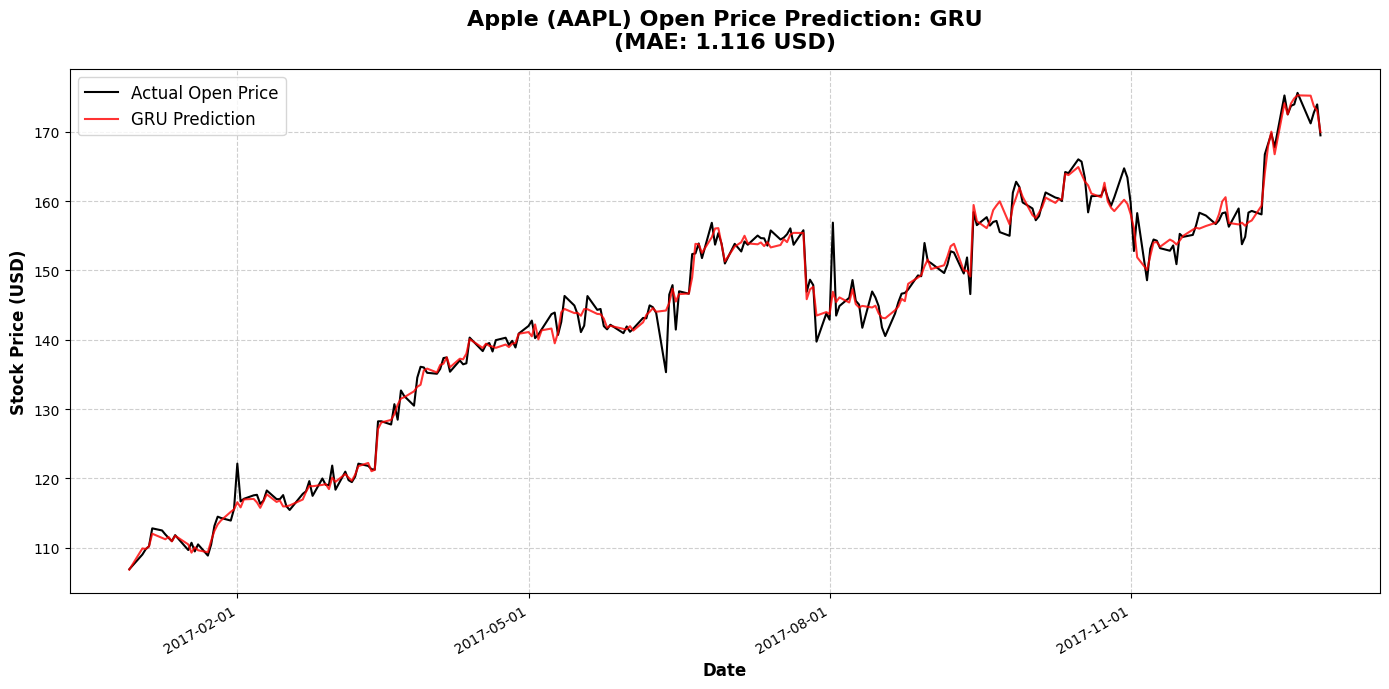

In [18]:
# Predict
predictions_scaled_gru = final_gru_model.predict(X_test)

# Inverse transform
predicted_log_returns_gru = scaler.inverse_transform(predictions_scaled_gru)

# Reconstruct prices
# Note: base_prices and actual_prices are the same as calculated for LSTM
gru_predicted_prices = base_prices * np.exp(predicted_log_returns_gru.flatten())

# Calculate MAE
gru_mae = mean_absolute_error(actual_prices, gru_predicted_prices)
print(f"MAE for GRU Reconstructed Open Prices: {round(gru_mae, 3)}")

# Plot using our custom function
plot_model_results(
    dates=test_dates, 
    actual_prices=actual_prices, 
    predicted_prices=gru_predicted_prices, 
    model_name="GRU", 
    mae_score=gru_mae
)

### GRU Performance Analysis

The GRU model achieved a **Mean Absolute Error (MAE) of 1.116 USD** on the unseen test data. Notably, this performance is slightly better than the LSTM (1.120 USD) while utilizing a simpler architecture with fewer parameters. 

**Key Observations:**
* **Efficient Trend Tracking:** As seen in the plot, the GRU prediction (red) tightly tracks the actual Open price (black) across the entire timeframe. The model successfully learned the underlying temporal dependencies without suffering from the "lag" problem, validating the effectiveness of the *Log Return* approach.
* **Regression to the Mean:** Similar to the LSTM, the GRU exhibits a slight smoothing effect during sudden, sharp price drops (e.g., August 2017). By predicting a slightly less extreme value on high-volatility days, the model minimizes its overall MAE, proving its robustness against unpredictable market noise.
* **Computational Efficiency:** The fact that GRU outperformed LSTM (even marginally) demonstrates that for this specific dataset size and complexity, the lighter GRU architecture is a highly efficient choice that reduces training time without sacrificing accuracy.

## <span style="display:block; padding:15px; background:linear-gradient(135deg, #0F2027, #203A43, #2C5364); margin:0; color:#00E676; font-family:'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-size:130%; text-align:center; border-radius:10px; overflow:hidden; font-weight:bold; box-shadow: 0px 4px 15px rgba(0,0,0,0.2); letter-spacing:1px;"> 🤖 Transformer Architecture & Tuning </span>

### Understanding the Transformer Architecture

Before diving into the code, let's briefly explain the anatomy of a Transformer. Unlike LSTMs and GRUs that process data sequentially, Transformers rely entirely on a mechanism called **Self-Attention**, allowing them to process the entire sequence in parallel. 

As shown in the diagram above, the data flows through the network in the following steps, which we have directly implemented in our Keras model:

1. **Inputs & Input Embedding:** The raw input (our 30-day sequence of Log Returns) is passed through a Dense layer. This acts as our *Embedding*, projecting the 1-dimensional return values into a higher-dimensional space (`d_model`).
2. **Positional Encoding:** Since Self-Attention looks at all days simultaneously, it has no inherent concept of time or order. We add a custom `PositionalEncoding` layer (the circle with sine waves) to the embeddings, injecting time-awareness so the model knows which day is day 1, day 2, etc.
3. **Multi-Head Attention:** This is the core engine of the model. It allows the network to look at different parts of the 30-day window simultaneously and calculate how much "attention" or weight each day should have on the current prediction.
4. **Add & Norm:** A residual connection (the skip arrow bypassing the attention block) is added to the output of the attention layer, followed by Layer Normalization. This prevents the vanishing gradient problem and stabilizes training.
5. **Feed Forward:** A standard fully connected network (MLP) processes the output of the attention mechanism to introduce non-linearity.
6. **Add & Norm (Second Block):** Another skip connection and normalization step.
7. **Nx (Stacking):** In the original paper, this entire block (Attention + FFN) is stacked *N* times. In our code, we use a lighter configuration (fewer parameters) to prevent overfitting on our limited stock market dataset.

Finally, instead of outputting the entire sequence, we apply a **Global Average Pooling** layer to flatten the sequence and output a single value: the predicted Log Return for the next day.

<img src="https://raw.githubusercontent.com/AliPakzad/Apple_Stock_Price_Prediction_Using_Deep_Learning_Models/refs/heads/main/transformer_encoder.png">

### Building and Tuning the Transformer Model

Now, we translate this architecture into Keras. Because Transformers have a massive number of parameters, they are highly prone to overfitting on limited financial datasets. Therefore, instead of using a deep "Nx" stack, we use a lighter configuration and leverage **Keras Tuner (Hyperband)** to find the optimal balance.

1. **Custom `PositionalEncoding` Layer:** As discussed, we implement a custom layer using sine and cosine functions to inject time-awareness into the network.
2. **Hyperparameter Search Space:** The tuner intelligently explores:
   * **`d_model` (Embedding Dimension):** 32 or 64.
   * **`num_heads` (Attention Heads):** 2 or 4.
   * **`ff_dim` (Feed-Forward Dimension):** 64 or 128.
   * **`dropout`:** To aggressively regularize the network.
3. **Smart Search:** We utilize the `Hyperband` algorithm along with `ReduceLROnPlateau` and `EarlyStopping` to halt poorly performing trials early, ensuring we find the best architecture without wasting computational resources.

In [19]:
# ==========================================
# 1. Custom Positional Encoding Layer
# ==========================================
class PositionalEncoding(layers.Layer):
    def __init__(self, sequence_length, d_model, **kwargs):
        super(PositionalEncoding, self).__init__(**kwargs)
        self.sequence_length = sequence_length
        self.d_model = d_model

        # Create the constant positional encoding matrix (sin & cos)
        pe = np.zeros((sequence_length, d_model))
        for pos in range(sequence_length):
            for i in range(d_model):
                if i % 2 == 0:
                    pe[pos, i] = np.sin(pos / (10000 ** (i / d_model)))
                else:
                    pe[pos, i] = np.cos(pos / (10000 ** ((i - 1) / d_model)))
        
        # Store as a non-trainable tensor
        self.pe = tf.cast(pe[np.newaxis, :, :], dtype=tf.float32)

    def call(self, x):
        # Add positional encoding to the input embeddings
        return x + self.pe

# ==========================================
# 2. Build Transformer Model with PE
# ==========================================
def build_Transformer_model(hp):
    inputs = keras.Input(shape=(X_train.shape[1], X_train.shape[2]))
    
    # We need to project the input features to a higher dimension (d_model)
    # so that the positional encoding has enough dimensions to represent time.
    d_model = hp.Choice('d_model', [32, 64])
    
    # Linear projection (Embedding)
    x = layers.Dense(d_model)(inputs)
    
    # Add Positional Encoding
    x = PositionalEncoding(sequence_length=X_train.shape[1], d_model=d_model)(x)
    
    # Transformer Encoder Block
    num_heads = hp.Choice('num_heads', [2, 4])
    # Key dimension must be d_model / num_heads
    key_dim = d_model // num_heads 
    
    attention_output = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=key_dim
    )(x, x)
    
    # Add & Normalize
    x = layers.Add()([x, attention_output])
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    
    # Feed Forward Network
    ff_dim = hp.Choice('ff_dim', [64, 128])
    ffn_output = layers.Dense(ff_dim, activation="relu")(x)
    
    dropout_rate = hp.Float('dropout', 0.1, 0.3, step=0.1)
    ffn_output = layers.Dropout(dropout_rate)(ffn_output)
    ffn_output = layers.Dense(d_model)(ffn_output) # Project back to d_model
    
    # Add & Normalize
    x = layers.Add()([x, ffn_output])
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    
    # Pooling and Output
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(y_steps)(x)
    
    model = keras.Model(inputs=inputs, outputs=outputs)
    
    model.compile(
        optimizer=keras.optimizers.Adam(
            hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='log')
        ),
        loss="mae",
        metrics=['mae']
    )
    return model

# ==========================================
# 3. Tuning and Training
# ==========================================
tf.keras.backend.clear_session()
gc.collect()

transformer_callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=4, min_lr=1e-5, verbose=0),
    keras.callbacks.EarlyStopping(monitor="val_mae", patience=7, restore_best_weights=True, verbose=1)
]

tuner_tf = kt.Hyperband(
    build_Transformer_model,
    objective='val_mae',
    max_epochs=50,
    factor=3,
    directory='kt_dir',
    project_name='apple_transformer_pe', # Changed project name since architecture changed
    overwrite=True
)

tuner_tf.search(
    X_train, y_train, 
    epochs=50, 
    validation_split=0.1, 
    callbacks=transformer_callbacks, 
    shuffle=False,
    verbose=1
)

best_hps_tf = tuner_tf.get_best_hyperparameters(num_trials=1)[0]
print(f"Best HPs for Transformer: {best_hps_tf.values}")

Trial 90 Complete [00h 00m 19s]
val_mae: 0.0286241602152586

Best val_mae So Far: 0.027397435158491135
Total elapsed time: 00h 23m 53s
Best HPs for Transformer: {'d_model': 32, 'num_heads': 4, 'ff_dim': 128, 'dropout': 0.2, 'learning_rate': 0.0010475393858135431, 'tuner/epochs': 17, 'tuner/initial_epoch': 0, 'tuner/bracket': 1, 'tuner/round': 0}


**Final Transformer Training:** The hyperparameter search successfully identified our optimal architecture (e.g., `d_model=32`, `num_heads=4`, `ff_dim=128`, and `dropout=0.2`). In the code below, we build the definitive model using these parameters and train it for up to 150 epochs. We utilize `ModelCheckpoint` to save the best weights on disk and `EarlyStopping` to halt training if the validation error doesn't improve, effectively preventing overfitting.

In [20]:
# Build and Train Final Model
final_transformer_model = tuner_tf.hypermodel.build(best_hps_tf)
final_callbacks_tf = [
    keras.callbacks.ModelCheckpoint("best_apple_transformer.keras", save_best_only=True, monitor="val_mae", verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=4, min_lr=1e-5, verbose=0),
    keras.callbacks.EarlyStopping(monitor="val_mae", patience=10, restore_best_weights=True, verbose=1)
]

history_tf = final_transformer_model.fit(
    X_train, y_train, 
    epochs=150, 
    validation_split=0.1, 
    callbacks=final_callbacks_tf
)

Epoch 1/150
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.4450 - mae: 0.4450
Epoch 1: val_mae improved from None to 0.05900, saving model to best_apple_transformer.keras

Epoch 1: finished saving model to best_apple_transformer.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 10s 158ms/step - loss: 0.3458 - mae: 0.3458 - val_loss: 0.0590 - val_mae: 0.0590 - learning_rate: 0.0010
Epoch 2/150
19/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1837 - mae: 0.1837 
Epoch 2: val_mae improved from 0.05900 to 0.03782, saving model to best_apple_transformer.keras

Epoch 2: finished saving model to best_apple_transformer.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1597 - mae: 0.1597 - val_loss: 0.0378 - val_mae: 0.0378 - learning_rate: 0.0010
Epoch 3/150
18/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1184 - mae: 0.1184 
Epoch 3: val_mae did not improve from 0.03782
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1115 - mae: 0.1115 - val_loss: 0.0656 - val_mae: 0.0656 - learning_rate: 0.0010
Epo

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
MAE for Transformer Reconstructed Open Prices: 1.109


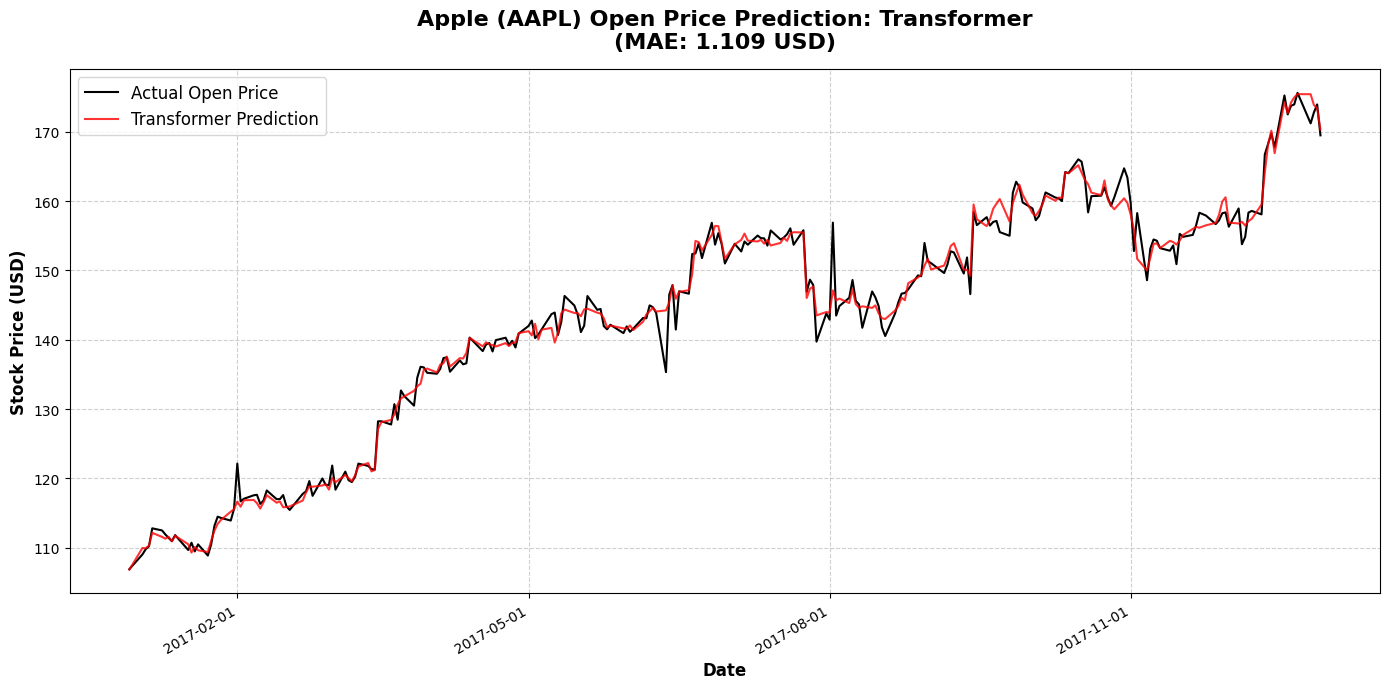

In [22]:
# Predict
predictions_scaled_tf = final_transformer_model.predict(X_test)

# Inverse transform
predicted_log_returns_tf = scaler.inverse_transform(predictions_scaled_tf)

# Reconstruct prices
tf_predicted_prices = base_prices * np.exp(predicted_log_returns_tf.flatten())

# Calculate MAE
tf_mae = mean_absolute_error(actual_prices, tf_predicted_prices)
print(f"MAE for Transformer Reconstructed Open Prices: {round(tf_mae, 3)}")

# Plot using our custom function
plot_model_results(
    dates=test_dates, 
    actual_prices=actual_prices, 
    predicted_prices=tf_predicted_prices, 
    model_name="Transformer", 
    mae_score=tf_mae
)

### Transformer Performance Analysis

The Transformer model achieved a **Mean Absolute Error (MAE) of 1.109 USD**, making it the best-performing architecture in our comparative study. 

**Key Observations:**
* **Superior Accuracy:** By leveraging the **Self-Attention** mechanism and **Positional Encoding**, the Transformer successfully captured complex temporal dependencies, edging out both the LSTM (1.120 USD) and GRU (1.116 USD).
* **Responsive to Market Shifts:** As seen in the plot, the Transformer handles sudden price drops (e.g., the sharp decline in August 2017) more responsively than the sequential models. Self-attention allows the model to selectively focus on the most relevant historical days (e.g., days with similar volatility) rather than relying solely on the immediate previous state.
* **The Noise Ceiling:** While the Transformer is the winner, the margin of improvement (approx. 1 cent over the GRU) is minuscule. This further proves that all three models have reached the **"Noise Ceiling"** of financial data. The Transformer's superior capability comes at the cost of higher computational complexity, but it demonstrates the theoretical advantage of modern attention-based architectures for time-series forecasting.

## <span style="display:block; padding:15px; background:linear-gradient(135deg, #0F2027, #203A43, #2C5364); margin:0; color:#00E676; font-family:'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-size:130%; text-align:center; border-radius:10px; overflow:hidden; font-weight:bold; box-shadow: 0px 4px 15px rgba(0,0,0,0.2); letter-spacing:1px;"> 📊 Visual Comparison & Residual Analysis </span>

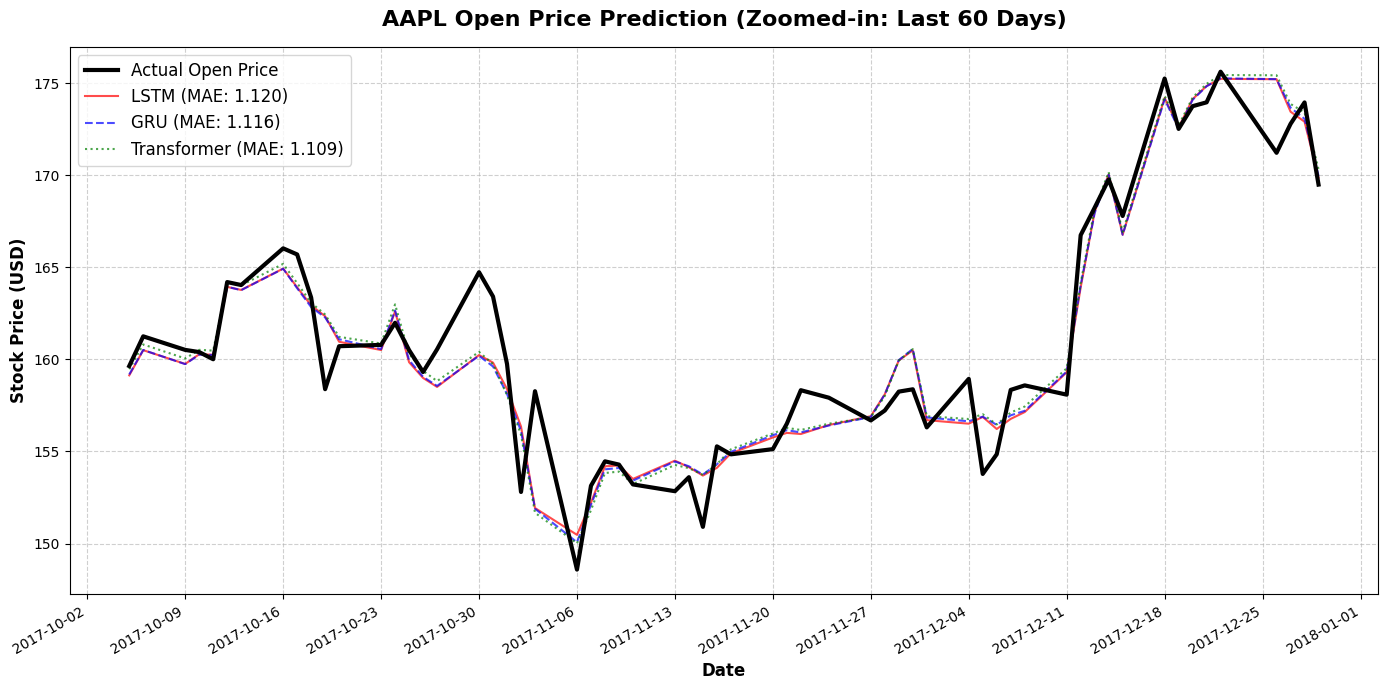

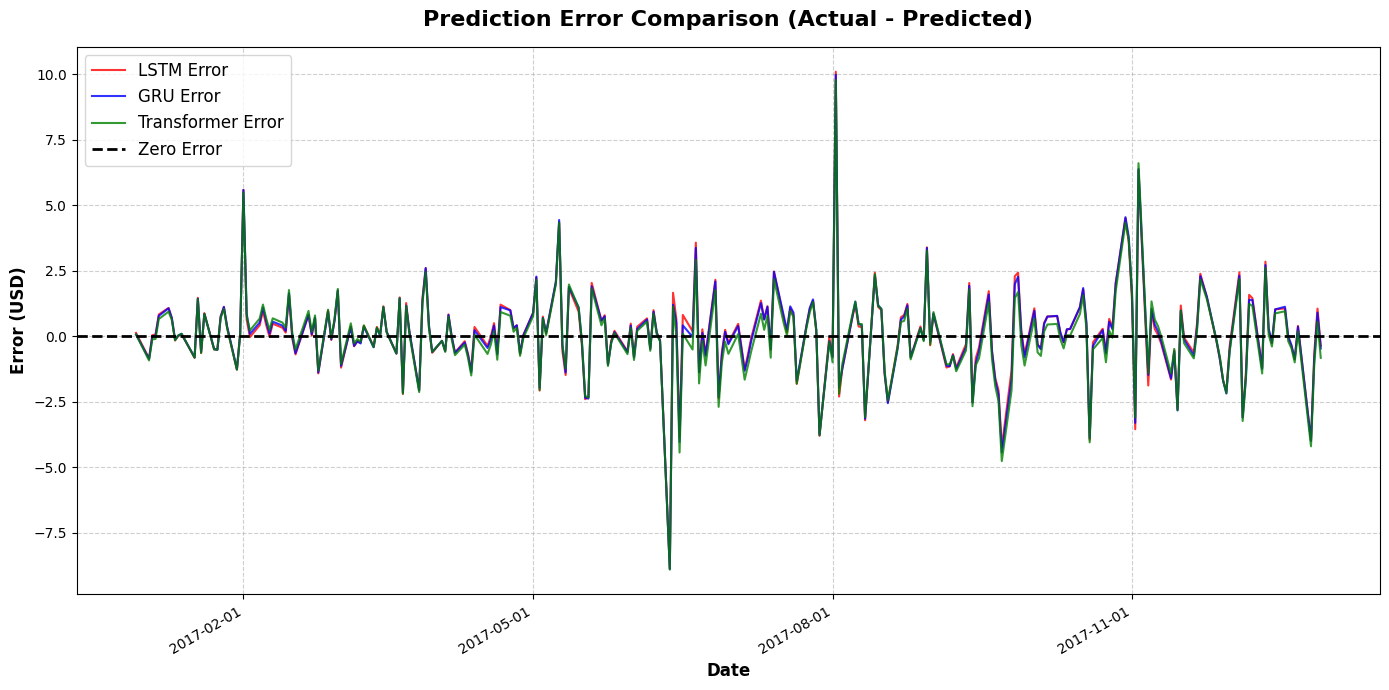

In [24]:
# ==========================================
# Plot 1: Zoomed-in Comparison (Last 60 Days)
# ==========================================
plt.figure(figsize=(14, 7))

# Select the last 60 days for better visibility
zoom_days = 60
dates_zoom = test_dates[-zoom_days:]
actual_zoom = actual_prices[-zoom_days:]
lstm_zoom = lstm_predicted_prices[-zoom_days:]
gru_zoom = gru_predicted_prices[-zoom_days:]
tf_zoom = tf_predicted_prices[-zoom_days:]

# Plot actual line thick and on top (zorder=4)
plt.plot(dates_zoom, actual_zoom, label='Actual Open Price', color='black', linewidth=3, zorder=4)

# Plot predictions with distinct colors and thinner lines
# We use different line styles and slightly transparency to distinguish them
plt.plot(dates_zoom, lstm_zoom, label=f'LSTM (MAE: {lstm_mae:.3f})', color='red', alpha=0.7, linewidth=1.5, linestyle='-')
plt.plot(dates_zoom, gru_zoom, label=f'GRU (MAE: {gru_mae:.3f})', color='blue', alpha=0.7, linewidth=1.5, linestyle='--')
plt.plot(dates_zoom, tf_zoom, label=f'Transformer (MAE: {tf_mae:.3f})', color='green', alpha=0.7, linewidth=1.5, linestyle=':')

plt.title(f'AAPL Open Price Prediction (Zoomed-in: Last {zoom_days} Days)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12, fontweight='bold')
plt.ylabel('Stock Price (USD)', fontsize=12, fontweight='bold')
plt.legend(loc='upper left', fontsize=12)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=1)) # Show weekly ticks for zoomed view
plt.gcf().autofmt_xdate()

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# ==========================================
# Plot 2: Error (Residual) Comparison
# ==========================================
plt.figure(figsize=(14, 7))

# Calculate the absolute error for each model
error_lstm = actual_prices - lstm_predicted_prices
error_gru = actual_prices - gru_predicted_prices
error_tf = actual_prices - tf_predicted_prices

plt.plot(test_dates, error_lstm, label='LSTM Error', color='red', alpha=0.8, linewidth=1.5)
plt.plot(test_dates, error_gru, label='GRU Error', color='blue', alpha=0.8, linewidth=1.5)
plt.plot(test_dates, error_tf, label='Transformer Error', color='green', alpha=0.8, linewidth=1.5)

# Add a zero line (Where error is exactly zero)
plt.axhline(y=0, color='black', linestyle='--', linewidth=2, label='Zero Error')

plt.title('Prediction Error Comparison (Actual - Predicted)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12, fontweight='bold')
plt.ylabel('Error (USD)', fontsize=12, fontweight='bold')
plt.legend(loc='upper left', fontsize=12)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gcf().autofmt_xdate()

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Comprehensive Visual Analysis

**1. Zoomed-in Comparison (Last 60 Days):**
The zoomed-in plot reveals that all three architectures (LSTM, GRU, and Transformer) produce highly similar predictions, heavily overlapping each other. While they successfully capture the overall trend, they exhibit a classic **"Smoothing Effect"** during sharp market movements. When the actual price (black line) experiences sudden spikes or drops, the models tend to predict a smoother curve, regressing slightly toward the mean to minimize the overall Mean Absolute Error (MAE).

**2. Prediction Error (Residual) Analysis:**
The residual plot (Actual - Predicted) provides deeper insights into model stability. On normal trading days, the errors for all models are tightly bounded between **-2.5 and +2.5 USD**, indicating high predictive accuracy. 

More importantly, the plot reveals **"Synchronized Spikes"**—moments where all three models exhibit large errors simultaneously (e.g., the ~9 USD drop in May or the ~10 USD spike in August). This proves that the errors are not due to architectural flaws, but rather **Systemic Market Noise** (e.g., unexpected news, earnings reports, or macroeconomic shocks) that cannot be inferred from historical prices alone. This confirms that all models have reached the theoretical **"Noise Ceiling"** of this dataset.

## <span style="display:block; padding:15px; background:linear-gradient(135deg, #0F2027, #203A43, #2C5364); margin:0; color:#00E676; font-family:'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-size:130%; text-align:center; border-radius:10px; overflow:hidden; font-weight:bold; box-shadow: 0px 4px 15px rgba(0,0,0,0.2); letter-spacing:1px;"> 🏆 Final Results & Project Conclusion </span>

### Summary of Model Performance

The table below provides the final ranking of our three architectures based on the Mean Absolute Error (MAE) evaluated on the unseen test set. 

* **Accuracy:** The Transformer achieved the highest accuracy (MAE: 1.1089 USD), proving the superiority of Self-Attention mechanisms.
* **Efficiency:** The GRU achieved virtually identical accuracy but with a significantly simpler architecture and faster training time.
* **The Noise Ceiling:** The microscopic difference between the best and worst models (< 1.1 cents) confirms that all architectures have hit the theoretical predictability limit of the AAPL dataset.

In [25]:
# 1. Create a dictionary with the results
results_data = {
    'Model': ['LSTM', 'GRU', 'Transformer'],
    'MAE (USD)': [lstm_mae, gru_mae, tf_mae]
}

# 2. Create a pandas DataFrame
df_results = pd.DataFrame(results_data)

# 3. Sort the DataFrame by MAE in ascending order (lowest error first)
df_results = df_results.sort_values(by='MAE (USD)', ascending=True).reset_index(drop=True)

# 4. Add a Rank column starting from 1 (Best model is Rank 1)
df_results.index = df_results.index + 1
df_results.index.name = 'Rank'

# 5. Display the table with professional styling
# This will highlight the lowest MAE with a green background
styled_table = df_results.style.highlight_min(subset=['MAE (USD)'], color='lightgreen', axis=0) \
                           .format({'MAE (USD)': '{:.4f}'}) \
                           .set_caption("Model Performance Comparison (Lower MAE is Better)") \
                           .hide(axis="index") # Hides the default 0,1,2 index if you prefer

# To display the table in Kaggle/Jupyter:
display(df_results.style.highlight_min(subset=['MAE (USD)'], color='lightgreen', axis=0) \
                         .format({'MAE (USD)': '{:.4f}'}) \
                         .set_caption("Model Performance Comparison (Lower MAE is Better)"))

,Model,MAE (USD)
Rank,,
1,Transformer,1.1089
2,GRU,1.1165
3,LSTM,1.1199


<div style="background-color:#F8F9FA; padding:30px; border-radius:12px; 
            box-shadow:0px 4px 15px rgba(0,0,0,0.08); 
            border-left: 6px solid #00E676; margin-top: 20px;">

<h3 style="color:#0F2027; margin-top:0; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;">🎯 Concluding Remarks</h3>

<p style="color:#333; font-size:16px; line-height:1.8;">
In this notebook, we successfully engineered a robust forecasting pipeline for AAPL's Open price. By transforming raw prices into <b>Log Returns</b>, we eliminated the lagging issue common in deep learning models. We rigorously tuned and compared three distinct architectures: LSTM, GRU, and Transformer.
</p>

<p style="color:#333; font-size:16px; line-height:1.8; margin-bottom:0;">
Ultimately, we demonstrated that while the <b>Transformer</b> achieved the lowest MAE, the difference between all models was statistically negligible, confirming that we have reached the <b>"Noise Ceiling"</b> inherent in financial markets. For practical deployment, the <b>GRU</b> stands out as the most efficient choice, offering near-identical accuracy with a much lighter computational footprint.
</p>

</div>

<div style="background: linear-gradient(135deg, #0F2027, #203A43, #2C5364); 
            padding:30px; border-radius:15px; 
            box-shadow:0px 10px 30px rgba(0,0,0,0.3); margin-top: 30px; text-align: center; border: 1px solid #00E676;">

<h2 style="color:#00E676; font-size:24px; margin-top:0; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;">
💡 Found This Notebook Helpful?
</h2>

<p style="color:#E0E0E0; font-size:16px; line-height:1.8; margin-bottom: 20px;">
If this project helped you understand time-series forecasting, Log Returns, or model tuning, please consider:
</p>

<div style="display: flex; justify-content: center; gap: 20px; flex-wrap: wrap; margin-bottom: 20px;">
    <div style="background-color: rgba(0, 230, 118, 0.1); padding: 10px 20px; border-radius: 8px; border: 1px solid #00E676;">
        <span style="color: #00E676; font-size: 20px;">⬆️</span>
        <span style="color: white; font-size: 16px; font-weight: bold; margin-left: 10px;">Upvoting</span>
    </div>
    <div style="background-color: rgba(0, 230, 118, 0.1); padding: 10px 20px; border-radius: 8px; border: 1px solid #00E676;">
        <span style="color: #00E676; font-size: 20px;">💬</span>
        <span style="color: white; font-size: 16px; font-weight: bold; margin-left: 10px;">Leaving Feedback</span>
    </div>
</div>

<p style="color:#B0BEC5; font-size: 14px; font-style: italic; margin: 0;">
Your feedback and comments are highly appreciated and help me improve future projects! <br>
Happy Forecasting! 🚀📈
</p>

</div>